# Gaussian processes: the continuous-trajectory problem

A **Gaussian process (GP)** is a probability distribution over functions. We write

\[
f(t)\sim GP(m(t),k(t,t')).
\]

For any finite set of query times \(t_1,\ldots,t_n\),

\[
[f(t_1),\ldots,f(t_n)]^\top\sim\mathcal N(m,K),
\qquad K_{ij}=k(t_i,t_j).
\]

The kernel is therefore not merely a similarity score: it defines which functions the prior considers plausible.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
from lifetime_clinical.tutorials.textbook import gp_posterior

## Common kernels: assumptions about trajectories

Write \(r=|t-t'|\). The following stationary kernels depend on the separation between times rather than their absolute position. We use unit marginal variance, a lengthscale \(\ell=1\), and period \(P=3\) below.

| Kernel | Covariance \(k(t,t')\) | Typical prior behaviour |
|---|---|---|
| RBF / squared exponential | \(\exp[-r^2/(2\ell^2)]\) | Very smooth functions; nearby times strongly covary. |
| Matérn \(\nu=1/2\) / exponential | \(\exp[-r/\ell]\) | Continuous but rough, non-differentiable paths. |
| Matérn \(\nu=3/2\) | \((1+\sqrt{3}r/\ell)\exp[-\sqrt{3}r/\ell]\) | Once mean-square differentiable; less smooth than RBF. |
| Periodic | \(\exp[-2\sin^2(\pi r/P)/\ell^2]\) | Repeating patterns: covariance returns to its maximum every period. |

The **top row** shows covariance with the function value at time zero. The **bottom row** shows three sampled functions from each zero-mean GP prior. The lengthscale controls how quickly a trajectory can vary; the variance controls its vertical scale. These are illustrative assumptions, not fitted clinical patterns. A purely periodic kernel assumes exact repetition; combining it with other kernels can allow patterns to evolve.


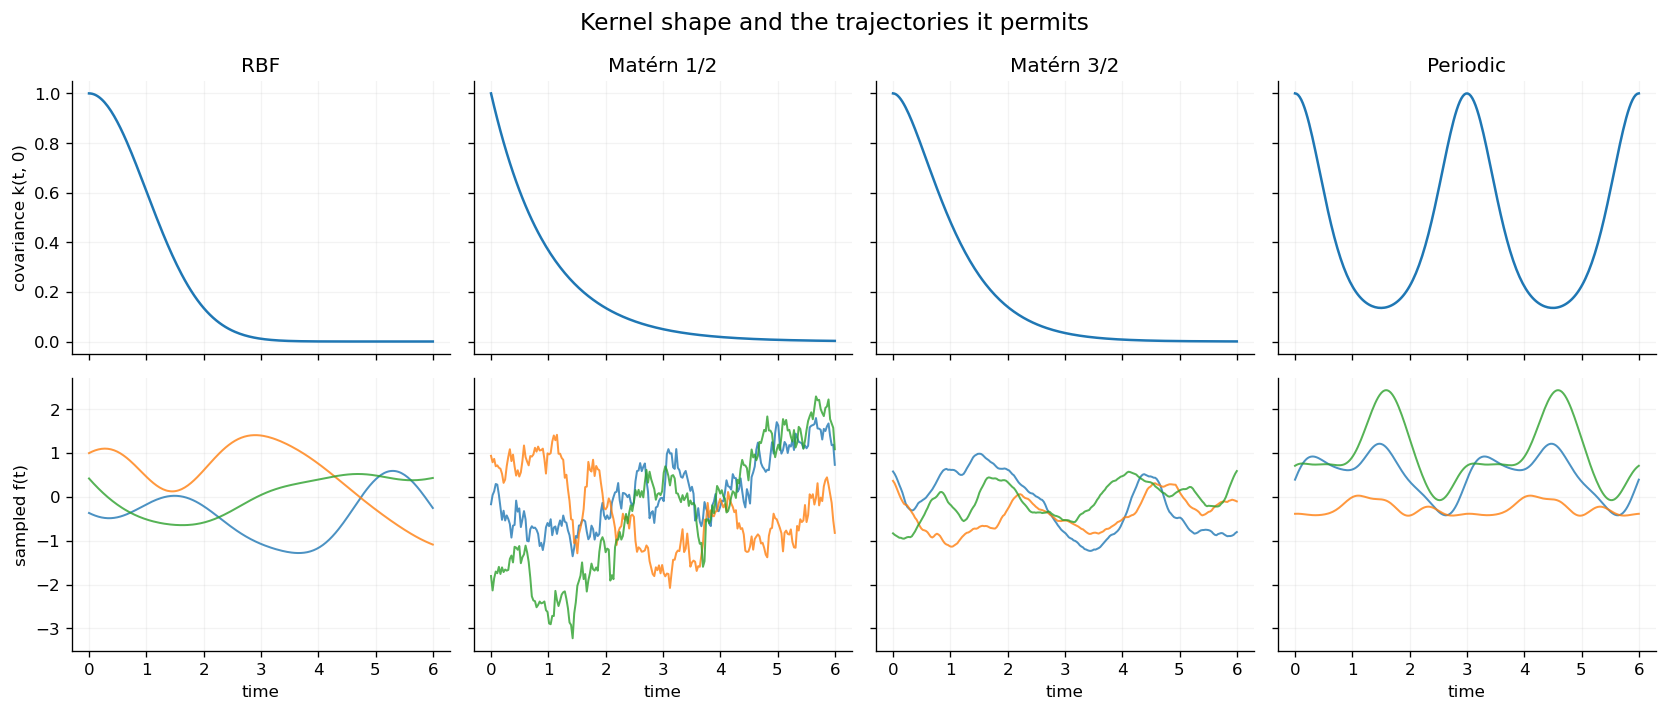

In [2]:
times = np.linspace(0, 6, 220)
lengthscale, period = 1.0, 3.0

def rbf(r):
    return np.exp(-0.5 * (r / lengthscale)**2)

def matern_half(r):
    return np.exp(-r / lengthscale)

def matern_three_halves(r):
    z = np.sqrt(3) * r / lengthscale
    return (1 + z) * np.exp(-z)

def periodic(r):
    return np.exp(-2 * np.sin(np.pi * r / period)**2 / lengthscale**2)

kernels = [("RBF", rbf), ("Matérn 1/2", matern_half),
           ("Matérn 3/2", matern_three_halves), ("Periodic", periodic)]
fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharex=True, sharey="row")
kernel_rng = np.random.default_rng(19)
separations = np.abs(times[:, None] - times[None, :])
for col, (name, kernel) in enumerate(kernels):
    axes[0, col].plot(times, kernel(times))
    axes[0, col].set(title=name, ylim=(-0.05, 1.05))
    covariance = kernel(separations)
    # Small numerical jitter stabilises the factorisation; it is not observation noise.
    factor = np.linalg.cholesky(covariance + 1e-8 * np.eye(len(times)))
    samples = factor @ kernel_rng.standard_normal((len(times), 3))
    axes[1, col].plot(times, samples, alpha=.8, linewidth=1.2)
    axes[1, col].set(xlabel="time")
    for row in range(2):
        axes[row, col].grid(alpha=.15)
axes[0, 0].set(ylabel="covariance k(t, 0)")
axes[1, 0].set(ylabel="sampled f(t)")
fig.suptitle("Kernel shape and the trajectories it permits", fontsize=14)
fig.tight_layout()
plt.show()


## Textbook regression example

With Gaussian observation noise

\[
y_i=f(t_i)+\epsilon_i,\qquad \epsilon_i\sim\mathcal N(0,\sigma_n^2),
\]

the posterior remains Gaussian. For test points \(t_*\),

\[
\mu_* = K_{*X}(K_{XX}+\sigma_n^2I)^{-1}y,
\]

\[
\Sigma_* = K_{**}-K_{*X}(K_{XX}+\sigma_n^2I)^{-1}K_{X*}.
\]

Notice that the observation times do **not** have to lie on a regular grid.

Why? The covariance matrix is built by evaluating \(k(t_i,t_j)\) at the **actual pair of observation times**, not by assuming a fixed step between rows. For example, observations at ages 20, 20.3 and 24 simply give a \(3\times3\) covariance matrix using those ages. The kernel sees the different time separations and adjusts their covariance accordingly. Prediction uses \(K_{*X}\), the covariance between any query times and those observed times, so query times can also be arbitrary.

The regular grid used for the plot below is only a convenient set of prediction locations for drawing a smooth curve. We neither resample the observations nor fill gaps before conditioning the GP. With a local kernel such as RBF, uncertainty typically grows in wide gaps and far from measurements. This does not by itself model *why* measurements were taken at particular times; an informative sampling process requires additional modelling.

The displayed posterior formulas assume a zero prior mean. With a nonzero mean, replace \(y\) by \(y-m_X\) and add \(m_*\) to the posterior mean.


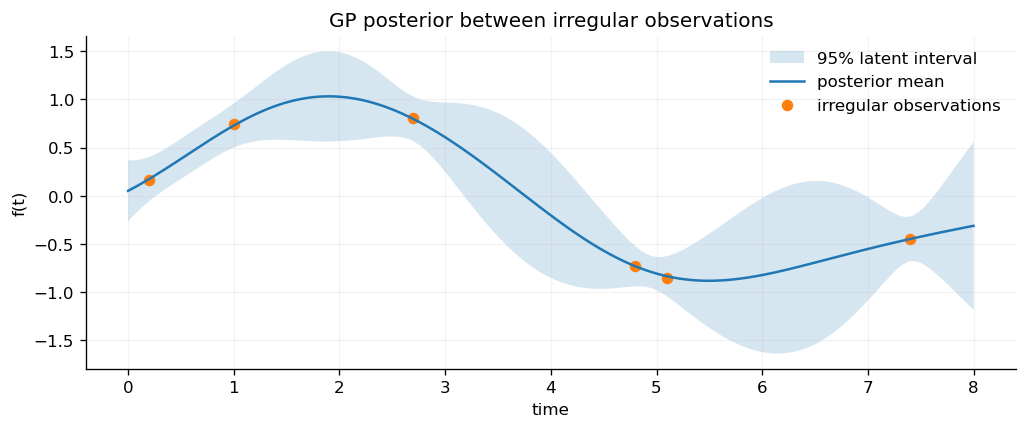

In [3]:
rng=np.random.default_rng(7)
x=np.array([0.2,1.0,2.7,4.8,5.1,7.4])
y=np.sin(x*.8)+rng.normal(0,.10,len(x))
xg=np.linspace(0,8,300); mean,cov=gp_posterior(x,y,xg,noise=.12,lengthscale=1.25)
sd=np.sqrt(np.clip(np.diag(cov),0,None))
fig,ax=plt.subplots(figsize=(10,3.6)); ax.fill_between(xg,mean-1.96*sd,mean+1.96*sd,alpha=.18,label="95% latent interval")
ax.plot(xg,mean,label="posterior mean"); ax.scatter(x,y,s=35,label="irregular observations")
ax.set(xlabel="time",ylabel="f(t)",title="GP posterior between irregular observations"); ax.legend(frameon=False); ax.grid(alpha=.15); plt.show()

## Why the GP is attractive for clinical physiology

A biomarker such as blood pressure is conceptually a time-varying quantity even when we do not measure it. A GP can infer

\[
p(f_d(t)\mid\text{measurements})
\]

for an arbitrary age \(t\), including interpolation between visits and prospective prediction. Here **\(f_d(t)\) is the latent, noise-free value of physiological feature \(d\) at age \(t\)**: for example, \(d=1\) might index systolic blood pressure, \(d=2\) glucose, and \(d=3\) creatinine. A recorded measurement is \(y_i=f_{d_i}(t_i)+\epsilon_i\), so uncertainty about the latent trajectory is distinct from measurement noise. A future measurement's predictive variance also includes that noise.

### Multi-output Gaussian processes (MOGPs)

A **multi-output GP** models a vector of functions jointly,

\[
\mathbf f(t)=[f_1(t),\ldots,f_D(t)]^\top,
\]

so any finite collection of values, across both times and features, has a joint Gaussian distribution. Its covariance kernel takes two time–feature pairs:

\[
k((t,d),(t',d'))=\operatorname{Cov}(f_d(t),f_{d'}(t')).
\]

When \(d=d'\), this describes a feature's temporal covariance. When \(d\ne d'\), it describes **cross-feature covariance**: how deviations from one feature's mean co-vary with deviations from another feature's mean, possibly at different ages. Separate independent GPs set these cross-feature blocks to zero; a MOGP can learn nonzero blocks. Positive covariance means deviations tend to move together, while negative covariance means they tend to move in opposite directions. Covariance is not evidence of causation.

One simple construction is a separable kernel:

\[
k((t,d),(t',d'))=B_{dd'}\,k_{\mathrm{time}}(t,t'),
\qquad B\succeq0.
\]

The temporal kernel controls dependence across ages. The positive-semidefinite **coregionalization matrix** \(B\) controls feature variances on its diagonal and cross-feature covariance off its diagonal. Requiring \(B\succeq0\) ensures that this construction gives valid covariance matrices; arbitrary pairwise coefficients need not do so. A more flexible linear model of coregionalization uses \(\sum_q B^{(q)}_{dd'}k_q(t,t')\), allowing different shared temporal patterns.

Each observation has its own pair \((t_i,d_i)\), giving

\[
K_{ij}=k((t_i,d_i),(t_j,d_j)).
\]

Consequently, BP, glucose and creatinine do **not** need to be measured at the same times. If the model learns a relationship between two features, a glucose measurement can update the BP posterior through their cross-covariance, as well as updating glucose itself. If their cross-covariance is zero, that direct information-sharing disappears. In practice, features with different units are often standardised before fitting, and their relationship must be learned from data rather than assumed from their clinical names.


## Clinical complications

| Clinical property | GP behaviour |
|---|---|
| Irregular sampling | **Natural strength.** A GP accepts arbitrary observation times directly. |
| Unmeasured times | Not missing rows: they are simply unobserved function values to infer. |
| Different variables measured at different times | Multi-output GPs can use cross-variable covariance. |
| Outliers / skew / heavy tails | Standard Gaussian likelihood is restrictive; transformed or robust likelihoods are needed. |
| Recurrent event timing | A GP is not a point-process model; it does not by itself model event occurrence times. |
| Right censoring of event times | Not naturally part of ordinary GP regression. |
| Unknown pre-study physiology | The posterior before entry is prior-driven; it cannot recover an unobserved life history from nothing. |
| Long cohorts | Exact GP operations scale cubically in the number of observations; sparse/inducing approximations may be needed. |

**Where GPs excel:** continuous-time interpolation, uncertainty between sparse observations, and joint longitudinal prediction.

**Where they fall short for our full problem:** event timing and flexible non-Gaussian observations. We will combine the GP with learned representations and flows rather than ask it to solve the whole clinical timeline alone.
Further reading: [Gaussian Processes for Machine Learning, Chapter 4](https://gaussianprocess.org/gpml/chapters/RW4.pdf) and [Kernels for Vector-Valued Functions: a Review](https://arxiv.org/abs/1106.6251).
